# 01 · First look at negative prices

First exploration of the interim tables: what negative prices look like, when they happen, and how well AEMO's own day-ahead forecast catches them.

- **Input:** `data/interim/` (built by `make data`)
- **Time:** NEM time (UTC+10, no daylight saving); timestamps mark the **end** of each interval

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from negprice.config import INTERIM_DATA_DIR

price = pd.read_parquet(INTERIM_DATA_DIR / "dispatchprice.parquet")        # actual price, every 5 min
demand = pd.read_parquet(INTERIM_DATA_DIR / "dispatchregionsum.parquet")   # actual demand, every 5 min
pv = pd.read_parquet(INTERIM_DATA_DIR / "rooftop_pv_actual.parquet")       # rooftop solar, every 30 min
pv = pv[pv["TYPE"] == "MEASUREMENT"]
price.head()

,SETTLEMENTDATE,REGIONID,RRP
0,2021-10-01 00:05:00,NSW1,43.64049
1,2021-10-01 00:10:00,NSW1,54.74070
2,2021-10-01 00:15:00,NSW1,62.43194
3,2021-10-01 00:20:00,NSW1,55.01017
4,2021-10-01 00:25:00,NSW1,54.54025


## 1. One week in SA

What a typical spring week looks like: prices fall below zero around midday, when rooftop solar pushes demand on the grid down.

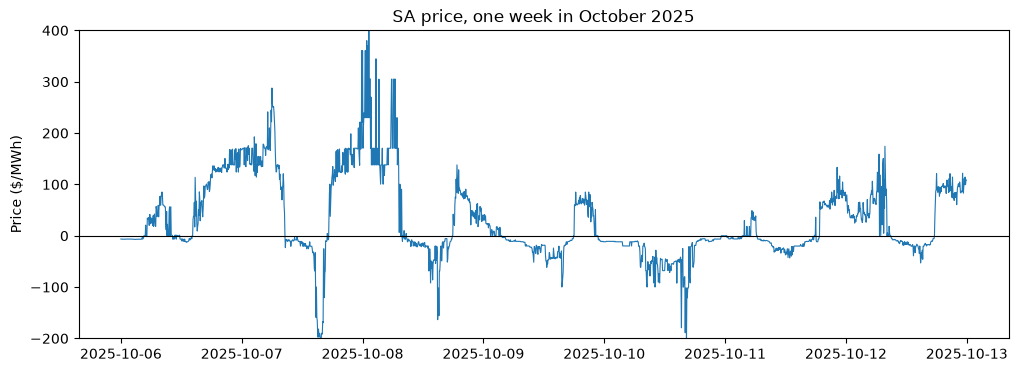

In [2]:
start, end = "2025-10-06", "2025-10-13"
sa = price[(price["REGIONID"] == "SA1") & (price["SETTLEMENTDATE"] >= start) & (price["SETTLEMENTDATE"] < end)]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sa["SETTLEMENTDATE"], sa["RRP"], lw=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-200, 400)
ax.set_ylabel("Price ($/MWh)")
ax.set_title("SA price, one week in October 2025");

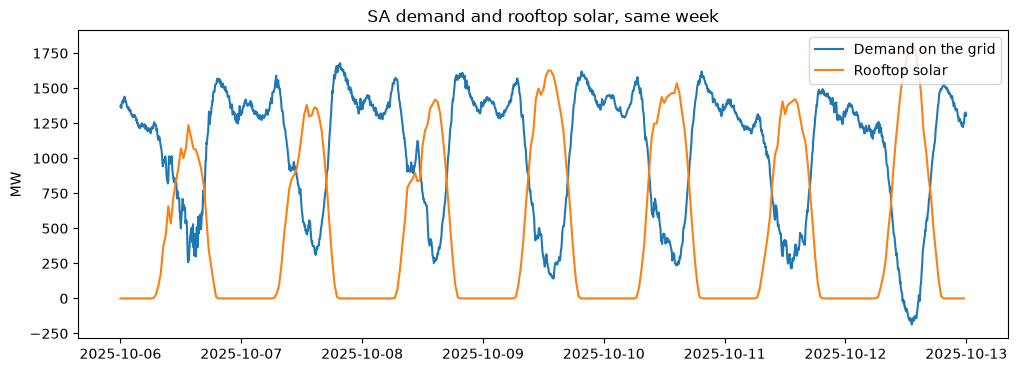

In [3]:
d = demand[(demand["REGIONID"] == "SA1") & (demand["SETTLEMENTDATE"] >= start) & (demand["SETTLEMENTDATE"] < end)]
p = pv[(pv["REGIONID"] == "SA1") & (pv["INTERVAL_DATETIME"] >= start) & (pv["INTERVAL_DATETIME"] < end)]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d["SETTLEMENTDATE"], d["TOTALDEMAND"], label="Demand on the grid")
ax.plot(p["INTERVAL_DATETIME"], p["POWER"], label="Rooftop solar")
ax.set_ylabel("MW")
ax.set_title("SA demand and rooftop solar, same week")
ax.legend();

## 2. When are prices negative?

Share of 5-minute intervals with a negative price, by the hour the interval starts in.

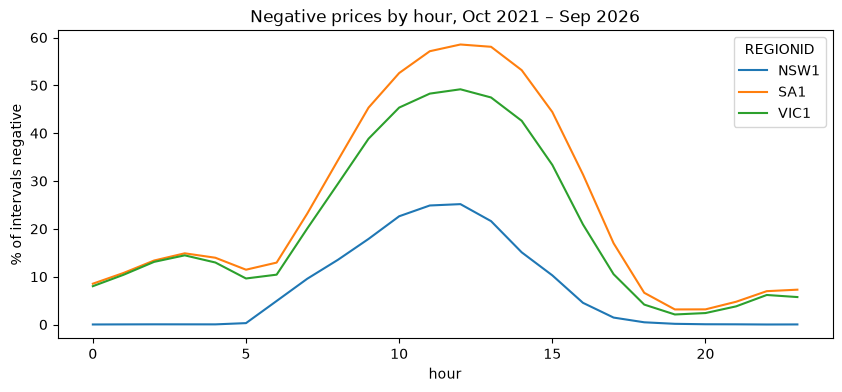

In [4]:
price["hour"] = (price["SETTLEMENTDATE"] - pd.Timedelta("5min")).dt.hour   # hour the interval starts in
price["negative"] = price["RRP"] < 0

share = price.groupby(["hour", "REGIONID"])["negative"].mean().unstack() * 100
share.plot(figsize=(10, 4), ylabel="% of intervals negative", title="Negative prices by hour, Oct 2021 – Sep 2026");

In [5]:
price["year"] = price["SETTLEMENTDATE"].dt.year
(price.groupby(["year", "REGIONID"])["negative"].mean().unstack() * 100).round(1)

REGIONID,NSW1,SA1,VIC1
year,,,
2021,4.5,26.9,22.2
2022,3.0,18.7,13.9
2023,6.4,24.7,21.7
2024,7.8,25.1,21.2
2025,14.4,30.4,24.0
2026,4.4,23.9,20.8


**Findings**

- Negative prices are a **midday solar** phenomenon: peak at 11:00–13:00 (SA ~58%, VIC ~49%, NSW ~25% of intervals). SA and VIC also see ~10–15% overnight (wind); NSW almost never goes negative at night.
- By year: SA 19–30%, VIC 14–24%, NSW 3–14% of intervals. NSW jumped to 14% in 2025.
- 2021 covers Oct–Dec only and 2026 Jan–Sep only, so those two years aren't comparable with full years (seasonality).

## 3. AEMO's day-ahead forecast (predispatch, 13:00 run on D-1)

The benchmark to beat. Actual 5-minute prices are averaged to half-hours (interval-end labels: the half-hour ending 12:30 holds the intervals ending 12:05 … 12:30) and joined to the forecast.

In [6]:
fc = pd.read_parquet(INTERIM_DATA_DIR / "predispatch_price.parquet")
fc.head()

,RUN_DATETIME,DATETIME,REGIONID,RRP
0,2021-09-30 13:00:00,2021-10-01 00:30:00,NSW1,66.03006
1,2021-09-30 13:00:00,2021-10-01 01:00:00,NSW1,64.98390
2,2021-09-30 13:00:00,2021-10-01 01:30:00,NSW1,58.00000
3,2021-09-30 13:00:00,2021-10-01 02:00:00,NSW1,55.01013
4,2021-09-30 13:00:00,2021-10-01 02:30:00,NSW1,55.01010


In [7]:
price["DATETIME"] = price["SETTLEMENTDATE"].dt.ceil("30min")
actual = price.groupby(["REGIONID", "DATETIME"], as_index=False)["RRP"].mean()

both = actual.merge(fc, on=["REGIONID", "DATETIME"], suffixes=("_actual", "_forecast"))
print(len(actual), "actual half-hours |", len(both), "with a forecast")
both.head()

262944 actual half-hours | 258480 with a forecast


,REGIONID,DATETIME,RRP_actual,RUN_DATETIME,RRP_forecast
0,NSW1,2021-10-01 00:30:00,54.228943,2021-09-30 13:00:00,66.03006
1,NSW1,2021-10-01 01:00:00,54.991435,2021-09-30 13:00:00,64.98390
2,NSW1,2021-10-01 01:30:00,55.194425,2021-09-30 13:00:00,58.00000
3,NSW1,2021-10-01 02:00:00,53.904143,2021-09-30 13:00:00,55.01013
4,NSW1,2021-10-01 02:30:00,55.663323,2021-09-30 13:00:00,55.01010


The 4,464 half-hours without a forecast are AEMO's predispatch archive gap (target days 2 Oct – 1 Nov 2022).

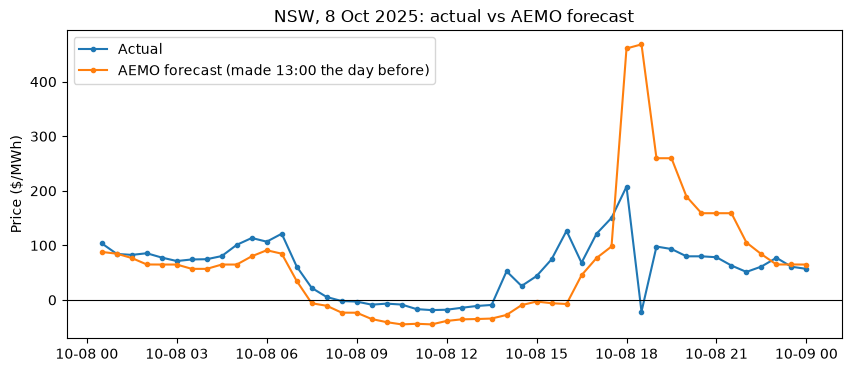

In [8]:
day = pd.Timestamp("2025-10-08")
one = both[(both["REGIONID"] == "NSW1") & (both["DATETIME"] > day) & (both["DATETIME"] <= day + pd.Timedelta("1D"))]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(one["DATETIME"], one["RRP_actual"], marker="o", ms=3, label="Actual")
ax.plot(one["DATETIME"], one["RRP_forecast"], marker="o", ms=3, label="AEMO forecast (made 13:00 the day before)")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Price ($/MWh)")
ax.set_title("NSW, 8 Oct 2025: actual vs AEMO forecast")
ax.legend();

In [9]:
both["neg_actual"] = both["RRP_actual"] < 0
both["neg_forecast"] = both["RRP_forecast"] < 0

for region, g in both.groupby("REGIONID"):
    table = pd.crosstab(g["neg_forecast"], g["neg_actual"])
    recall = table.loc[True, True] / table[True].sum() * 100
    precision = table.loc[True, True] / table.loc[True].sum() * 100
    print(region)
    print(table)
    print(f"Caught {recall:.0f}% of actual negative half-hours (recall); "
          f"right {precision:.0f}% of the times it said negative (precision)\n")

NSW1
neg_actual    False  True 
neg_forecast              
False         75759   1147
True           4582   4672
Caught 80% of actual negative half-hours (recall); right 50% of the times it said negative (precision)

SA1
neg_actual    False  True 
neg_forecast              
False         61173   5022
True           3281  16684
Caught 77% of actual negative half-hours (recall); right 84% of the times it said negative (precision)

VIC1
neg_actual    False  True 
neg_forecast              
False         64359   4569
True           3476  13756
Caught 75% of actual negative half-hours (recall); right 80% of the times it said negative (precision)



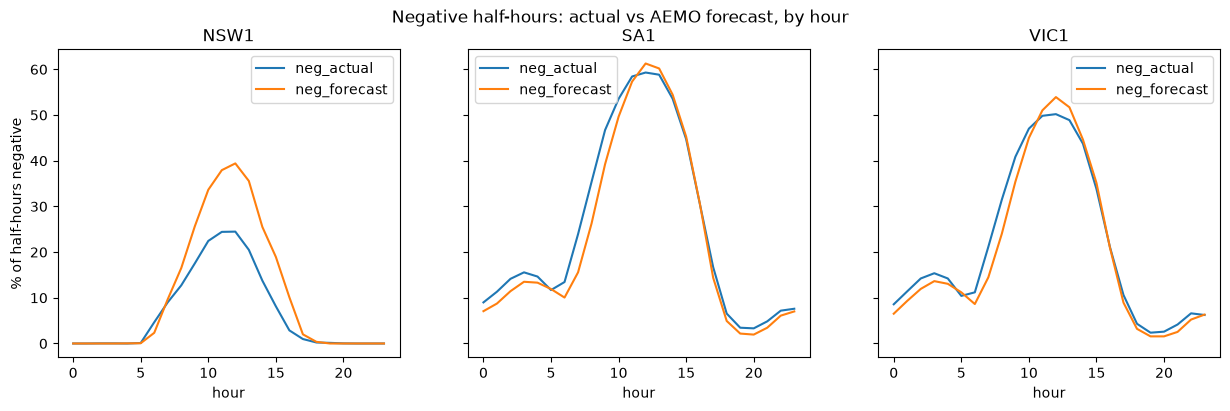

In [10]:
both["hour"] = (both["DATETIME"] - pd.Timedelta("30min")).dt.hour   # hour the half-hour starts in

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (region, g) in zip(axes, both.groupby("REGIONID")):
    (g.groupby("hour")[["neg_actual", "neg_forecast"]].mean() * 100).plot(ax=ax, title=region)
axes[0].set_ylabel("% of half-hours negative")
fig.suptitle("Negative half-hours: actual vs AEMO forecast, by hour");

**Findings**

| Region | Recall | Precision |
|---|---|---|
| NSW | 80% | 50% |
| SA | 77% | 84% |
| VIC | 75% | 80% |

- AEMO's forecast is a strong baseline in SA and VIC.
- In NSW it **over-forecasts** negative prices: at midday it predicts ~39% negative half-hours against ~25% actual, so half of its "negative" calls are wrong.